<a href="https://colab.research.google.com/github/twyeh/university-physics/blob/main/%E5%96%AE%E6%93%BA%E5%AF%A6%E9%A9%97%E5%88%86%E6%9E%90%E7%AF%84%E4%BE%8B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 單擺實驗分析程式 (Pendulum Experiment Analysis)

本程式用於分析固定擺長下，多次測量單擺週期以求得重力加速度 $g$ 的實驗數據。

#### 物理原理
單擺的小角度運動週期公式為：
$$T = 2\pi \sqrt{\frac{L}{g}}$$

整理後可得重力加速度 $g$：
$$g =
4\pi^2 \frac{L}{T^2}$$

#### 誤差傳播 (Error Propagation)
若擺長 $L$ 的標準不確定度為 $\sigma_L$，平均週期 $T$ 的標準不確定度為 $\sigma_T$，則 $g$ 的相對不確定度為：
$$\frac{\sigma_g}{g} = \sqrt{\left(\frac{\sigma_L}{L}\right)^2 + \left(2\frac{\sigma_T}{T}\right)^2}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# --- 1. 輸入實驗數據 ---
# 請在此處輸入您的實驗數據
L = 1.0  # 擺長 (公尺, m)
sigma_L = 0.002  # 擺長測量不確定度 (公尺, m)，例如捲尺最小刻度的一半或標準差

# 每次測量 N 次擺動的總時間，再除以 N 得到單次週期 T (秒, s)
# 這裡假設已經是單次週期的多次測量值
T_measurements = np.array([2.01, 1.99, 2.02, 2.00, 1.98, 2.01, 2.03, 1.99])

# --- 2. 數據統計與分析 ---
# 計算週期的平均值、標準差與平均值標準誤差 (Standard Error of the Mean)
T_mean = np.mean(T_measurements)
T_std = np.std(T_measurements, ddof=1) # 樣本標準差
sigma_T = T_std / np.sqrt(len(T_measurements)) # 平均值的不確定度

# 計算重力加速度 g
g_mean = 4 * (np.pi**2) * L / (T_mean**2)

# 計算 g 的不確定度 (誤差傳播)
relative_error_g = np.sqrt((sigma_L / L)**2 + (2 * sigma_T / T_mean)**2)
sigma_g = g_mean * relative_error_g

# --- 3. 輸出分析結果 ---
print("=== 單擺實驗分析結果 ===")
print(f"數據筆數: {len(T_measurements)} 筆")
print(f"擺長 L: {L:.4f} ± {sigma_L:.4f} m")
print(f"平均週期 T: {T_mean:.4f} ± {sigma_T:.4f} s (標準差: {T_std:.4f} s)")
print(f"計算所得重力加速度 g: {g_mean:.4f} ± {sigma_g:.4f} m/s²")
print(f"相對誤差: {relative_error_g * 100:.2f}%")

=== 單擺實驗分析結果 ===
數據筆數: 8 筆
擺長 L: 1.0000 ± 0.0020 m
平均週期 T: 2.0038 ± 0.0060 s (標準差: 0.0169 s)
計算所得重力加速度 g: 9.8327 ± 0.0617 m/s²
相對誤差: 0.63%


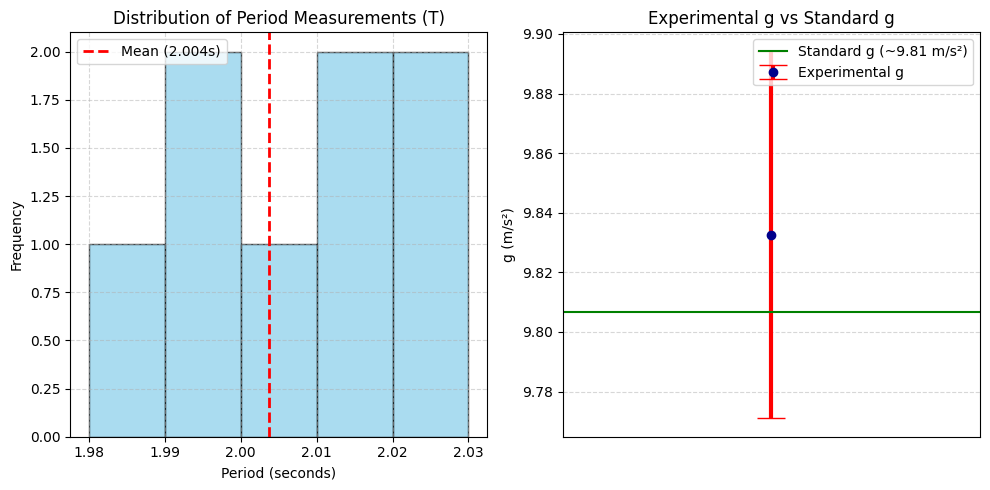

In [2]:
# --- 4. 繪製測量數據分布與信賴區間 ---
plt.figure(figsize=(10, 5))

# 繪製單次週期測量值分佈
plt.subplot(1, 2, 1)
plt.hist(T_measurements, bins=5, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(T_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean ({T_mean:.3f}s)')
plt.title('Distribution of Period Measurements (T)')
plt.xlabel('Period (seconds)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 繪製計算出 g 的誤差範圍與標準值(9.80665)比較
plt.subplot(1, 2, 2)
plt.errorbar(1, g_mean, yerr=sigma_g, fmt='o', color='darkblue', ecolor='red', elinewidth=3, capsize=10, label='Experimental g')
plt.axhline(9.80665, color='green', linestyle='-', label='Standard g (~9.81 m/s²)')
plt.xlim(0.5, 1.5)
plt.xticks([])
plt.title('Experimental g vs Standard g')
plt.ylabel('g (m/s²)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()